# NN_L4_fmnist_featuremaps

**One Fashion-MNIST test image (ankle boot) and the eight most active feature maps of blocks 1 and 3 of the trained CNN.**

Neural Networks and Deep Learning (NN), Lecture 4 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/NEURAL_BIZ/blob/main/Quantlets/L4/NN_L4_fmnist_featuremaps/NN_L4_fmnist_featuremaps.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/'

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
# course chart style: transparent background, no gridlines, legend at the bottom outside the axes, four-digit years
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.labelsize': 11, 'legend.fontsize': 10.5, 'legend.frameon': False,
    'lines.linewidth': 1.4, 'font.family': 'DejaVu Sans'})
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
PAL = {'data': '#2a78d6', 'model': '#eb6834', 'benchmark': '#1baf7a', 'alt': '#eda100',
       'train': '#2a78d6', 'valid': '#eb6834', 'test': '#6250d6', 'positive': '#e34948', 'negative': '#2a78d6'}


def legend_bottom(fig, ncol=4):
    h, l_ = [], []
    for ax in fig.axes:
        for hh, ll in zip(*ax.get_legend_handles_labels()):
            if ll not in l_:
                h.append(hh); l_.append(ll)
    if h:
        fig.legend(h, l_, loc='lower center', ncol=min(ncol, len(h)), bbox_to_anchor=(0.5, 0.0), frameon=False)


def show(key, label, value):
    # print a number of the slide; [key] = its name in lectures/Lk/Lk_numbers.json
    print(f'{label} = {value}   [{key}]')

Feature maps of block 1 (14 x 14, after pooling) and block 3 (7 x 7).

size of the block-3 maps = 7   [fmnist.fmap_l3_size]


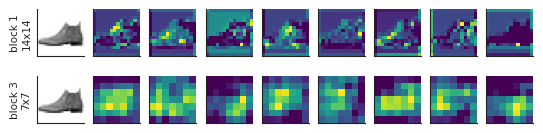

In [3]:
import json, urllib.request
_F = 'fmnist_featuremaps_results.json'
R = json.load(open(_F)) if os.path.isfile(_F) else json.load(urllib.request.urlopen(REPO + 'Quantlets/L4/NN_L4_fmnist_featuremaps/' + _F))
img = np.array(R['img']); maps = [np.array(R['m1']), np.array(R['m3'])]
show('fmnist.fmap_l3_size', 'size of the block-3 maps', maps[1].shape[1])
fig, axes = plt.subplots(2, 9, figsize=(6.4, 1.6))
for r in range(2):
    axes[r, 0].imshow(img, cmap='gray_r')
    order = np.argsort(-maps[r].mean((1, 2)))[:8]
    for c in range(8): axes[r, c + 1].imshow(maps[r][order[c]], cmap='viridis')
    for ax in axes[r]: ax.set_xticks([]); ax.set_yticks([])
axes[0, 0].set_ylabel('block 1\n14x14', fontsize=7.5); axes[1, 0].set_ylabel('block 3\n7x7', fontsize=7.5)
fig.savefig('fmnist_featuremaps.png', dpi=200, transparent=True, bbox_inches='tight')
plt.show()